# Random Forest Optimisation on Encoding A — Bridging the Top-5 to Top-1 Gap on CUB-200-2011

This notebook repeats [`randomForestOptimisation.ipynb`](randomForestOptimisation.ipynb) on **encoding A** (the 312 binary attributes only), the same input as every other classical model in the project. The original notebook uses encoding C (A plus 28 `notvis::` hidden-body-part flags).

**What changes from the original:**
- Every model is trained on the `312` attributes (`385` columns once the 73 regional features are added) instead of the `340` / `413` columns of encoding C.
- **Step 0** is exactly the tuned forest from [`randomForest_encodingA.ipynb`](randomForest_encodingA.ipynb): `750` trees, Gini, `max_depth=30`, `max_features=0.1`, `min_samples_leaf=2`, `bootstrap=True`. Steps 1–4 keep `max_features=0.1` so every step builds on the same base forest.
- The original **Step 5 (visibility-aware Bayes profile) is left out**: it needs the `notvis::` flags to know which body parts are hidden, and encoding A records a hidden attribute as `0`, the same as absent. The original Step 6 does not use Step 5 (it blends Step 4 with logistic regression), so it is kept here as **Step 5**.
- The certainty ablations (D1–D3) are run without the `notvis::` flags.
- All other settings (blend weights, specialist forests, logistic regression `C=0.25`) are unchanged from the original.

In [`randomForest_encodingA.ipynb`](randomForest_encodingA.ipynb), the tuned forest reaches **45.18%** Top-1 accuracy (`0.4324` macro-F1) but **72.04%** Top-5 accuracy. On roughly **1 in 4 test images**, the true species is already in the forest's top 5 but loses the #1 spot to a close relative (e.g. *Herring Gull* vs *California Gull*, *Common Tern* vs *Forster's Tern*).

### Why the Baseline Random Forest Loses Sibling Tie-Breakers
1. **Bootstrap Sample Dropout (`bootstrap=True`)**: Bootstrap sampling leaves out $1/e \approx 36.8\%$ of the training data per tree. With only `~30` training images per species (`~24` per CV fold), each tree sees only **15–19 unique examples per species**.
2. **Anatomical Boundary Noise**: Single-worker MTurk annotations often disagree on adjacent body parts (e.g. yellow on `has_crown_color` vs `has_forehead_color`, or `has_breast_color` vs `has_belly_color` vs `has_underparts_color`).
3. **Single-Resolution Leaf Trade-Off**: `min_samples_leaf=2` smooths out noise for common species, whereas `min_samples_leaf=1` is needed to isolate rare attribute combinations.
4. **The Feature Subset Bottleneck Within Bird Families**: Every tree spends its upper levels separating all **200 species** into coarse groups. Deep in the tree, few samples remain and each split checks only `0.1 × 312 ≈ 31` random features, often missing the subtle trait that separates sibling species in the same family.

---

### Experimental Protocol (Zero Test Leakage)
- All feature encodings, hyperparameter choices and ensemble weights are evaluated with **5-fold `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`** strictly within the training split.
- The held-out test set (`is_train == 0`) is used once, in **Section 4**.

## 1. Setup, Data Loading & Taxonomic Family Structure

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score, confusion_matrix

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

SEED = 42
ROOT = Path("..").resolve()
DATA_DIR = ROOT / "data"
# Dataset folder, found the same way as in dataPrep.ipynb: inside data/raw/, or CUB_200_2011/ at the repo root
CUB_DIR = next((p.parent for p in (ROOT / "data" / "raw").rglob("image_class_labels.txt")), ROOT / "CUB_200_2011")

META_COLS = ["image_id", "class_id", "class_name", "is_train"]

df_A = pd.read_csv(DATA_DIR / "cub_features_A.csv")
attr_cols = [c for c in df_A.columns if c not in META_COLS]

# Step 0 uses exactly the random forest selected in randomForest_encodingA.ipynb (5-fold CV on encoding A).
# Steps 1-4 keep the same global forest settings (max_features=0.1) so every step builds on the same base.
MAX_FEATURES = 0.1

print(f"Loaded Variant A: {df_A.shape[0]:,} images x {len(attr_cols)} binary attributes")
print(f"Official split   : {(df_A['is_train'] == 1).sum():,} train / {(df_A['is_train'] == 0).sum():,} test")

Loaded Variant A: 11,788 images x 312 binary attributes
Official split   : 5,994 train / 5,794 test


### 1.1 Extracting the 70 Taxonomic Bird Families
In our Week 4 project pitch feedback (`documentation/week4/projectPitchFeedback.md`), the lecturer noted the relationship between the **70 coarse bird families** and the **200 fine-grained species**. Every CUB `class_name` ends with its taxonomic family/group suffix (e.g., `059.California_Gull` $\rightarrow$ `Gull`, `158.Bay_breasted_Warbler` $\rightarrow$ `Warbler`).

Because this mapping is a fixed property of the 200 target class names, we can decompose 200-species classification hierarchically without any target leakage:

In [2]:
class_df = df_A[["class_id", "class_name"]].drop_duplicates().sort_values("class_id").reset_index(drop=True)
class_df["species_clean"] = class_df["class_name"].apply(lambda s: s.split(".", 1)[1].replace("_", " "))
class_df["family"] = class_df["class_name"].apply(lambda s: s.split(".")[-1].split("_")[-1])

families = sorted(class_df["family"].unique())
fam_to_id = {f: i for i, f in enumerate(families)}
class_to_fam = np.array([fam_to_id[f] for f in class_df["family"].values])  # shape (200,), maps class_id-1 -> family_id

fam_counts = class_df.groupby("family")["class_id"].count().sort_values(ascending=False)
multi_fam = fam_counts[fam_counts > 1]
single_fam = fam_counts[fam_counts == 1]

print(f"Total taxonomic families : {len(families)}")
print(f"Multi-species families   : {len(multi_fam)} families covering {multi_fam.sum()} / 200 species ({multi_fam.sum()/2:.1f}%)")
print(f"Single-species families  : {len(single_fam)} families covering {single_fam.sum()} / 200 species")
print("\nTop 10 largest bird families by number of species:")
print(fam_counts.head(10).to_frame(name="n_species").T)

Total taxonomic families : 70
Multi-species families   : 37 families covering 167 / 200 species (83.5%)
Single-species families  : 33 families covering 33 / 200 species

Top 10 largest bird families by number of species:
family     Warbler  Sparrow  Gull  Flycatcher  Tern  Vireo  Wren  Woodpecker  \
n_species       25       21     8           7     7      7     7           6   

family     Kingfisher  Grosbeak  
n_species           5         4  


## 2. Feature Engineering & Certainty Encoding Ablations (5-Fold CV)

Before changing the forest itself, we test two feature-level ideas with 5-fold cross-validation (`is_train == 1`, `300` trees per fold, `max_features=0.1`):

1. **Certainty-Weighted Feature Encodings (Variants D1, D2, D3)**:
   - Raw `image_attribute_labels_clean.txt` records 4 certainty levels: `1` (*not visible*), `2` (*guessing*), `3` (*probably*) and `4` (*definitely*).
   - **Variant D1 (Positive Confidence)**: Encodes `is_present = 1` as `0.33` (*guessing*), `0.67` (*probably*), `1.00` (*definitely*), and `0.0` otherwise.
   - **Variant D2 (Signed Confidence)**: Encodes present (`+0.33, +0.67, +1.00`) and absent (`-0.33, -0.67, -1.00`) confidence, with `0.0` for *not visible*.
   - **Variant D3 (`DROP_GUESSING_POSITIVES = True`)**: Tests the toggle in [`dataPrep.ipynb`](dataPrep.ipynb) that zeroes the `27,306` positive entries marked `certainty == 2` (*guessing*).
   - Unlike the encoding C notebook, none of these variants appends the `28` `notvis::` flags.
2. **Regional Binary Colour & Pattern Aggregations (`+73` Binary Features)**:
   - To absorb annotator disagreements across adjacent body parts, we add **binary (`0`/`1`) regional presence indicators** over 4 zones (`head`, `upper`, `under`, `all`) for each of the 15 colours (`60` columns) plus whole-bird presence for each of the 13 patterns (`13` columns). These are built only from the 312 attributes.
   - We also compare them with integer counts (`0..7` body parts sharing a colour).

In [3]:
# 1. Load raw certainty_id to construct Variants D1, D2, D3
raw_ial = pd.read_csv(
    CUB_DIR / "attributes" / "image_attribute_labels_clean.txt",
    sep=r"\s+",
    header=None,
    usecols=[0, 1, 2, 3],
    names=["image_id", "attribute_id", "is_present", "certainty_id"],
)
pres_piv = raw_ial.pivot(index="image_id", columns="attribute_id", values="is_present").values
cert_piv = raw_ial.pivot(index="image_id", columns="attribute_id", values="certainty_id").values

cert_w = np.where(cert_piv == 4, 1.0, np.where(cert_piv == 3, 0.67, np.where(cert_piv == 2, 0.33, 0.0)))

# Encoding A has no hidden-body-part flags, so the certainty variants are the 312 re-weighted attributes only
X_D1 = pres_piv * cert_w
X_D2 = np.where(cert_piv == 1, 0.0, np.where(pres_piv == 1, cert_w, -cert_w))
X_D3 = np.where((pres_piv == 1) & (cert_piv >= 3), 1.0, 0.0)

# 2. Construct Regional Binary Colour & Pattern Aggregations (73 binary features) + Integer Count Aggregations (28 count features)
groups = sorted(list({c.split("::")[0] for c in attr_cols}))
color_groups = [g for g in groups if "color" in g]
pattern_groups = [g for g in groups if "pattern" in g]

head_color_groups = ["has_forehead_color", "has_crown_color", "has_nape_color", "has_throat_color", "has_eye_color", "has_bill_color"]
upper_color_groups = ["has_back_color", "has_upperparts_color", "has_wing_color", "has_upper_tail_color"]
under_color_groups = ["has_breast_color", "has_belly_color", "has_underparts_color", "has_under_tail_color"]

colors = sorted(list({c.split("::")[1] for c in attr_cols if c.split("::")[0] in color_groups}))
patterns = sorted(list({c.split("::")[1] for c in attr_cols if c.split("::")[0] in pattern_groups}))

bin_agg_dict = {}
cnt_agg_dict = {}

for col_name in colors:
    for prefix, grp_list in [
        ("all", color_groups),
        ("head", head_color_groups),
        ("upper", upper_color_groups),
        ("under", under_color_groups),
    ]:
        cols = [f"{g}::{col_name}" for g in grp_list if f"{g}::{col_name}" in df_A.columns]
        if cols:
            bin_agg_dict[f"agg_{prefix}_color::{col_name}"] = (df_A[cols].sum(axis=1) > 0).astype(np.float32)
    all_c = [f"{g}::{col_name}" for g in color_groups if f"{g}::{col_name}" in df_A.columns]
    if all_c:
        cnt_agg_dict[f"cnt_color::{col_name}"] = df_A[all_c].sum(axis=1).astype(np.float32)

for pat_name in patterns:
    cols = [f"{g}::{pat_name}" for g in pattern_groups if f"{g}::{pat_name}" in df_A.columns]
    if cols:
        bin_agg_dict[f"agg_pat::{pat_name}"] = (df_A[cols].sum(axis=1) > 0).astype(np.float32)
        cnt_agg_dict[f"cnt_pat::{pat_name}"] = df_A[cols].sum(axis=1).astype(np.float32)

df_bin_agg = pd.DataFrame(bin_agg_dict, index=df_A.index)
df_cnt_agg = pd.DataFrame(cnt_agg_dict, index=df_A.index)

X_A = df_A[attr_cols].values
X_A_reg_bin = np.hstack([X_A, df_bin_agg.values])
X_A_reg_cnt = np.hstack([X_A, df_bin_agg.values, df_cnt_agg.values])

print(f"Regional Binary Aggregations : {df_bin_agg.shape[1]} binary features -> Augmented Variant A has {X_A_reg_bin.shape[1]} columns")
print(f"Regional Count Aggregations  : {df_cnt_agg.shape[1]} integer count features")

Regional Binary Aggregations : 73 binary features -> Augmented Variant A has 385 columns
Regional Count Aggregations  : 28 integer count features


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
is_train_off = df_A["is_train"].values == 1
y_all = df_A["class_id"].values
y_tr_off = y_all[is_train_off]

def eval_single_rf_cv(X_mat, mask, y_vec, bootstrap=True, min_samples_leaf=2, n_estimators=300):
    X_sub = X_mat[mask]
    oof_p = np.zeros((len(X_sub), 200), dtype=np.float64)
    for tr_idx, va_idx in cv.split(X_sub, y_vec):
        clf = RandomForestClassifier(
            n_estimators=n_estimators,
            criterion="gini",
            max_depth=30,
            max_features=MAX_FEATURES,
            min_samples_leaf=min_samples_leaf,
            bootstrap=bootstrap,
            random_state=SEED,
            n_jobs=-1,
        )
        clf.fit(X_sub[tr_idx], y_vec[tr_idx])
        oof_p[va_idx] = clf.predict_proba(X_sub[va_idx])
    preds = oof_p.argmax(axis=1) + 1
    acc = accuracy_score(y_vec, preds)
    f1 = f1_score(y_vec, preds, average="macro")
    top5 = top_k_accuracy_score(y_vec, oof_p, k=5, labels=np.arange(1, 201))
    return acc, f1, top5, oof_p

ablation_configs = [
    ("Variant A Baseline (Binary 0/1, bootstrap=True)", X_A, True),
    ("Variant D1: Positive Certainty Weights (0.33/0.67/1.0, bootstrap=True)", X_D1, True),
    ("Variant D2: Signed Certainty Weights (-1.0..+1.0, bootstrap=True)", X_D2, True),
    ("Variant D3: Drop Guessing Positives (cert==2 -> 0, bootstrap=True)", X_D3, True),
    ("Variant A + bootstrap=False (100% samples per tree)", X_A, False),
    ("Variant D1 + bootstrap=False", X_D1, False),
    ("Variant A + 73 Regional Binary Aggs + Integer Counts (bootstrap=False)", X_A_reg_cnt, False),
    ("Variant A + 73 Regional Binary Aggs Only (bootstrap=False) [SELECTED]", X_A_reg_bin, False),
]

ablation_rows = []
base_cv_acc = None
for label, X_mat, bs in ablation_configs:
    acc, f1, top5, _ = eval_single_rf_cv(X_mat, is_train_off, y_tr_off, bootstrap=bs, min_samples_leaf=2, n_estimators=300)
    if base_cv_acc is None:
        base_cv_acc = acc
    ablation_rows.append({
        "Configuration": label,
        "Features": X_mat.shape[1],
        "Bootstrap": bs,
        "5-Fold CV Top-1 (%)": round(acc * 100, 2),
        "Gain vs Baseline (%)": f"{(acc - base_cv_acc)*100:+.2f}%",
        "5-Fold CV Macro-F1": round(f1, 4),
        "5-Fold CV Top-5 (%)": round(top5 * 100, 2),
    })

df_ablation = pd.DataFrame(ablation_rows)
display(df_ablation)

,Configuration,Features,Bootstrap,5-Fold CV Top-1 (%),Gain vs Baseline (%),5-Fold CV Macro-F1,5-Fold CV Top-5 (%)
0,"Variant A Baseline (Binary 0/1, bootstrap=True)",312,True,44.39,+0.00%,0.4203,70.59
1,Variant D1: Positive Certainty Weights (0.33/0...,312,True,43.48,-0.92%,0.4135,70.54
2,Variant D2: Signed Certainty Weights (-1.0..+1...,312,True,41.64,-2.75%,0.3953,69.25
3,Variant D3: Drop Guessing Positives (cert==2 -...,312,True,43.46,-0.93%,0.4141,69.02
4,Variant A + bootstrap=False (100% samples per ...,312,False,44.14,-0.25%,0.4223,70.45
5,Variant D1 + bootstrap=False,312,False,43.94,-0.45%,0.4189,70.07
6,Variant A + 73 Regional Binary Aggs + Integer ...,413,False,44.14,-0.25%,0.4228,70.92
7,Variant A + 73 Regional Binary Aggs Only (boot...,385,False,44.78,+0.38%,0.4290,71.02


### Key Takeaways from Feature & Bootstrap Ablations
1. **Multi-Level Certainty Weights (`D1`, `D2`) Hurt Decision Trees**:
   - A binary `{0, 1}` column has one split point. Replacing it with `{0.0, 0.33, 0.67, 1.0}` lets trees split between *probably* and *definitely*. Because each image has a single annotator, such splits partition the data by **annotator confidence** rather than bird appearance (`-0.92` points CV on D1, `-2.75` on D2).
2. **Keep the Guessed Positives (`D3`)**:
   - Zeroing out *guessing* positives lowers CV accuracy by **`0.93` points** (`44.39%` $\rightarrow$ `43.46%`), so even low-confidence annotations carry signal.
3. **Disabling Bootstrap Alone Does Not Help on Encoding A**:
   - Unlike on encoding C (`+0.72` points), `bootstrap=False` slightly lowers CV accuracy on encoding A (`44.39%` $\rightarrow$ `44.14%`), although macro-F1 rises a little (`0.4203` $\rightarrow$ `0.4223`). The difference is well within fold noise.
4. **Binary Regional Aggregations Are the Best Feature Change**:
   - Adding the 73 binary regional features (with `bootstrap=False`) gives the best single forest in CV (`44.78%`, macro-F1 `0.4290`). Adding integer counts on top lowers it again (`44.14%`), for the same split-threshold reason as D1/D2.

## 3. Cumulative 5-Step Optimisation Pipeline (5-Fold CV Validation)

We validate the cumulative progression with 5-fold cross-validation (`is_train == 1`). Global forests use `max_features=0.1`, the setting chosen for encoding A in [`randomForest_encodingA.ipynb`](randomForest_encodingA.ipynb).

- **Step 0 — Baseline Tuned RF**: Variant A (`312` cols), `bootstrap=True`, `min_samples_leaf=2`, the exact forest from `randomForest_encodingA.ipynb`.
- **Step 1 — Disable Bootstrap Dropout**: Variant A (`312` cols), `bootstrap=False`, `min_samples_leaf=2`.
- **Step 2 — Add 73 Regional Binary Aggregations**: Augmented Variant A (`385` binary cols), `bootstrap=False`, `min_samples_leaf=2`.
- **Step 3 — Dual-Resolution Random Forest**: `0.60 * P(min_samples_leaf=2) + 0.40 * P(min_samples_leaf=1)` (`bootstrap=False`), combining smoothed multi-sample leaves with sharp 1-sample leaves for rare species.
- **Step 4 — Hierarchical 70-Family Specialist Random Forest (100% Pure Random Forests)**:
  - Decomposes species probability by Bayes' rule across the $70$ taxonomic families $F(c)$:
    $$P(y = c \mid x) = P\big(y \in F(c) \mid x\big) \cdot P\big(y = c \;\big|\; y \in F(c),\, x\big)$$
  - $P(y \in F \mid x)$ averages the Step 3 forest's family probability with a dedicated **70-Family Dual-Resolution RF**.
  - $P(y = c \mid y \in F(c), x)$ averages the Step 3 forest's within-family distribution with **37 Within-Family Specialist Random Forests** (`max_features=0.25`, `min_samples_leaf=1`, `bootstrap=False`), each trained only on the species of one family so every split separates sibling species.
- **Step 5 — Cross-Model Hybrid Ensemble (`55% Hierarchical RF + 45% L2 Logistic Regression`)**:
  - Blends Step 4 with L2-regularised logistic regression (`C=0.25`) fitted on the same 385 binary features. This is Step 6 of the encoding C notebook; its Step 5 (visibility-aware profile) needs the `notvis::` flags and is not used here.

In [5]:
y_fam_all = class_to_fam[y_all - 1]

STEP_NAMES = [
    "Step 0: Baseline Tuned RF (Variant A)",
    "Step 1: Single RF (bootstrap=False, Variant A)",
    "Step 2: Single RF (bootstrap=False, A + 73 Regional Aggs)",
    "Step 3: Dual-Resolution RF (leaf=1 & 2, A + 73 Reg Aggs)",
    "Step 4: Hierarchical 70-Family Specialist RF (100% Pure RF)",
    "Step 5: Hierarchical RF + Logistic Regression Ensemble",
]

def rf(min_samples_leaf, bootstrap, n_estimators, seed):
    return RandomForestClassifier(n_estimators=n_estimators, criterion="gini", max_depth=30, max_features=MAX_FEATURES,
                                  min_samples_leaf=min_samples_leaf, bootstrap=bootstrap, random_state=seed, n_jobs=-1)

def run_pipeline_fold(X_a_tr, X_aug_tr, y_tr, y_fam_tr, X_a_va, X_aug_va,
                      n_est_main=300, n_est_spec=250):
    # Step 0: Baseline RF - the tuned forest from randomForest_encodingA.ipynb
    rf0 = rf(2, True, n_est_main, SEED).fit(X_a_tr, y_tr)
    p_s0 = rf0.predict_proba(X_a_va)

    # Step 1: Single RF (bootstrap=False, Variant A)
    rf1 = rf(2, False, n_est_main, SEED).fit(X_a_tr, y_tr)
    p_s1 = rf1.predict_proba(X_a_va)

    # Step 2: Single RF (bootstrap=False, Variant A + 73 Regional Binary Aggs)
    rf2 = rf(2, False, n_est_main, SEED).fit(X_aug_tr, y_tr)
    p_s2 = rf2.predict_proba(X_aug_va)

    # Step 3: Dual-Resolution RF (0.60 * leaf=2 + 0.40 * leaf=1)
    rf2_l1 = rf(1, False, n_est_main, SEED + 1).fit(X_aug_tr, y_tr)
    p_s3 = 0.60 * p_s2 + 0.40 * rf2_l1.predict_proba(X_aug_va)

    # Step 4: Hierarchical 70-Family Specialist RF (100% Pure Random Forests)
    rf_fam2 = rf(2, False, n_est_main, SEED + 2).fit(X_aug_tr, y_fam_tr)
    rf_fam1 = rf(1, False, n_est_main, SEED + 3).fit(X_aug_tr, y_fam_tr)
    p_fam_rf = 0.60 * rf_fam2.predict_proba(X_aug_va) + 0.40 * rf_fam1.predict_proba(X_aug_va)

    p_spec = np.zeros((len(X_aug_va), 200), dtype=np.float64)
    for f_id in range(len(families)):
        f_classes = np.where(class_to_fam == f_id)[0] + 1
        if len(f_classes) == 1:
            p_spec[:, f_classes[0] - 1] = 1.0
        else:
            m_f = (y_fam_tr == f_id)
            spec_rf = RandomForestClassifier(
                n_estimators=n_est_spec, criterion="gini", max_depth=25, max_features=0.25,
                min_samples_leaf=1, bootstrap=False, random_state=SEED+100+f_id, n_jobs=-1
            )
            spec_rf.fit(X_aug_tr[m_f], y_tr[m_f])
            ps = spec_rf.predict_proba(X_aug_va)
            for local_i, c_id in enumerate(spec_rf.classes_):
                p_spec[:, c_id - 1] = ps[:, local_i]

    fam_from_glob = np.zeros((len(X_aug_va), len(families)), dtype=np.float64)
    for c_idx in range(200):
        fam_from_glob[:, class_to_fam[c_idx]] += p_s3[:, c_idx]
    p_glob_cond = p_s3 / np.clip(fam_from_glob[:, class_to_fam], 1e-12, None)
    p_fam_ens = 0.50 * fam_from_glob + 0.50 * p_fam_rf
    p_s4 = p_fam_ens[:, class_to_fam] * (0.50 * p_glob_cond + 0.50 * p_spec)

    # Step 5: Hierarchical RF + L2 Logistic Regression Soft-Voting Ensemble (55 / 45)
    # (Step 6 in randomForestOptimisation.ipynb; its Step 5 needs the hidden-body-part flags of encoding C and is left out.)
    lr = LogisticRegression(C=0.25, max_iter=500, random_state=SEED)
    lr.fit(X_aug_tr, y_tr)
    p_lr = lr.predict_proba(X_aug_va)
    p_s5 = 0.55 * p_s4 + 0.45 * p_lr

    return dict(zip(STEP_NAMES, [p_s0, p_s1, p_s2, p_s3, p_s4, p_s5])), p_fam_ens

# Run 5-fold CV on the Official Training Set
t0 = time.time()
step_names = STEP_NAMES
oof_preds_dict = {k: np.zeros((is_train_off.sum(), 200)) for k in step_names}
oof_fam_ens = np.zeros((is_train_off.sum(), len(families)))

X_a_off = X_A[is_train_off]
X_aug_off = X_A_reg_bin[is_train_off]
y_f_off = y_fam_all[is_train_off]

for tr_idx, va_idx in cv.split(X_a_off, y_tr_off):
    fold_out, fold_fam = run_pipeline_fold(
        X_a_off[tr_idx], X_aug_off[tr_idx], y_tr_off[tr_idx], y_f_off[tr_idx],
        X_a_off[va_idx], X_aug_off[va_idx],
        n_est_main=300, n_est_spec=250
    )
    for k in step_names:
        oof_preds_dict[k][va_idx] = fold_out[k]
    oof_fam_ens[va_idx] = fold_fam

fam_top1_cv = accuracy_score(y_f_off, oof_fam_ens.argmax(axis=1))
fam_top3_cv = top_k_accuracy_score(y_f_off, oof_fam_ens, k=3, labels=np.arange(len(families)))
print(f"5-Fold CV completed in {time.time() - t0:.1f}s")
print(f"70-Family Classification Accuracy (Stage-1 Family RF Ensemble): Top-1 = {fam_top1_cv*100:.2f}%, Top-3 = {fam_top3_cv*100:.2f}%\n")

cv_summary_rows = []
base_oof_acc = accuracy_score(y_tr_off, oof_preds_dict[step_names[0]].argmax(axis=1) + 1)
for k in step_names:
    p_mat = oof_preds_dict[k]
    preds = p_mat.argmax(axis=1) + 1
    acc = accuracy_score(y_tr_off, preds)
    f1 = f1_score(y_tr_off, preds, average="macro")
    top5 = top_k_accuracy_score(y_tr_off, p_mat, k=5, labels=np.arange(1, 201))
    cv_summary_rows.append({
        "Step & Model": k,
        "5-Fold CV Top-1 (%)": round(acc * 100, 2),
        "CV Gain vs Step 0": f"{(acc - base_oof_acc)*100:+.2f}%",
        "5-Fold CV Macro-F1": round(f1, 4),
        "5-Fold CV Top-5 (%)": round(top5 * 100, 2),
    })

df_cv_summary = pd.DataFrame(cv_summary_rows)
display(df_cv_summary)

5-Fold CV completed in 34.6s
70-Family Classification Accuracy (Stage-1 Family RF Ensemble): Top-1 = 62.11%, Top-3 = 80.56%



,Step & Model,5-Fold CV Top-1 (%),CV Gain vs Step 0,5-Fold CV Macro-F1,5-Fold CV Top-5 (%)
0,Step 0: Baseline Tuned RF (Variant A),44.39,+0.00%,0.4203,70.59
1,"Step 1: Single RF (bootstrap=False, Variant A)",44.14,-0.25%,0.4223,70.45
2,"Step 2: Single RF (bootstrap=False, A + 73 Reg...",44.78,+0.38%,0.4290,71.02
3,"Step 3: Dual-Resolution RF (leaf=1 & 2, A + 73...",45.06,+0.67%,0.4334,71.20
4,Step 4: Hierarchical 70-Family Specialist RF (...,46.08,+1.69%,0.4456,72.29
5,Step 5: Hierarchical RF + Logistic Regression ...,50.22,+5.82%,0.4955,75.71


## 4. Final Held-Out Test Set Evaluation

With every design choice fixed on 5-fold CV, we train the full-capacity models (`750` trees, matching [`randomForest_encodingA.ipynb`](randomForest_encodingA.ipynb)) on the complete official training split and evaluate once on the held-out test set.

We also compute **McNemar's exact binomial test** against **Step 0 (Baseline Tuned RF)** to check statistical significance.

In [6]:
def evaluate_test_split(mask_col, n_trees_main):
    tr_mask = df_A[mask_col].values == 1
    te_mask = ~tr_mask
    y_tr = y_all[tr_mask]
    y_te = y_all[te_mask]
    y_fam_tr = y_fam_all[tr_mask]
    y_fam_te = y_fam_all[te_mask]

    t_start = time.time()
    test_probas, fam_proba_te = run_pipeline_fold(
        X_A[tr_mask], X_A_reg_bin[tr_mask], y_tr, y_fam_tr,
        X_A[te_mask], X_A_reg_bin[te_mask],
        n_est_main=n_trees_main, n_est_spec=300
    )
    elapsed = time.time() - t_start

    fam_acc = accuracy_score(y_fam_te, fam_proba_te.argmax(axis=1))
    fam_top3 = top_k_accuracy_score(y_fam_te, fam_proba_te, k=3, labels=np.arange(len(families)))

    base_preds = test_probas[step_names[0]].argmax(axis=1) + 1
    base_acc = accuracy_score(y_te, base_preds)
    base_correct = (base_preds == y_te)

    rows = []
    for k in step_names:
        proba = test_probas[k]
        preds = proba.argmax(axis=1) + 1
        acc = accuracy_score(y_te, preds)
        f1 = f1_score(y_te, preds, average="macro")
        top5 = top_k_accuracy_score(y_te, proba, k=5, labels=np.arange(1, 201))
        new_correct = (preds == y_te)
        only_new = int((new_correct & ~base_correct).sum())
        only_base = int((~new_correct & base_correct).sum())
        pval = binomtest(only_new, only_new + only_base, 0.5).pvalue if (only_new + only_base) > 0 else 1.0
        rows.append({
            "Step & Model": k,
            "Test Top-1 (%)": round(acc * 100, 2),
            "Gain vs Step 0": f"{(acc - base_acc)*100:+.2f}%",
            "Test Macro-F1": round(f1, 4),
            "Test Top-5 (%)": round(top5 * 100, 2),
            "Wins / Losses vs Step 0": f"+{only_new} / -{only_base}",
            "McNemar p-value": f"{pval:.2e}",
        })
    return pd.DataFrame(rows), test_probas, y_te, fam_acc, fam_top3, elapsed

print("Evaluating on Official CUB Split (5,994 train / 5,794 test, 750 trees)...")
df_test_off, probas_off, y_te_off, fam_acc_off, fam_top3_off, t_off = evaluate_test_split("is_train", 750)
print(f"Done in {t_off:.1f}s | 70-Family Test Accuracy: Top-1 = {fam_acc_off*100:.2f}%, Top-3 = {fam_top3_off*100:.2f}%")
display(df_test_off)


Evaluating on Official CUB Split (5,994 train / 5,794 test, 750 trees)...


Done in 16.4s | 70-Family Test Accuracy: Top-1 = 62.29%, Top-3 = 81.26%


,Step & Model,Test Top-1 (%),Gain vs Step 0,Test Macro-F1,Test Top-5 (%),Wins / Losses vs Step 0,McNemar p-value
0,Step 0: Baseline Tuned RF (Variant A),45.18,+0.00%,0.4324,72.04,+0 / -0,1.00e+00
1,"Step 1: Single RF (bootstrap=False, Variant A)",45.46,+0.28%,0.4380,71.69,+148 / -132,3.70e-01
2,"Step 2: Single RF (bootstrap=False, A + 73 Reg...",45.91,+0.72%,0.4442,72.23,+241 / -199,5.05e-02
3,"Step 3: Dual-Resolution RF (leaf=1 & 2, A + 73...",46.05,+0.86%,0.4467,72.39,+248 / -198,2.02e-02
4,Step 4: Hierarchical 70-Family Specialist RF (...,46.53,+1.35%,0.4540,72.87,+319 / -241,1.12e-03
5,Step 5: Hierarchical RF + Logistic Regression ...,51.07,+5.89%,0.5067,76.79,+583 / -242,2.97e-33


## 5. Visualisation of Progression & Within-Family Error Analysis

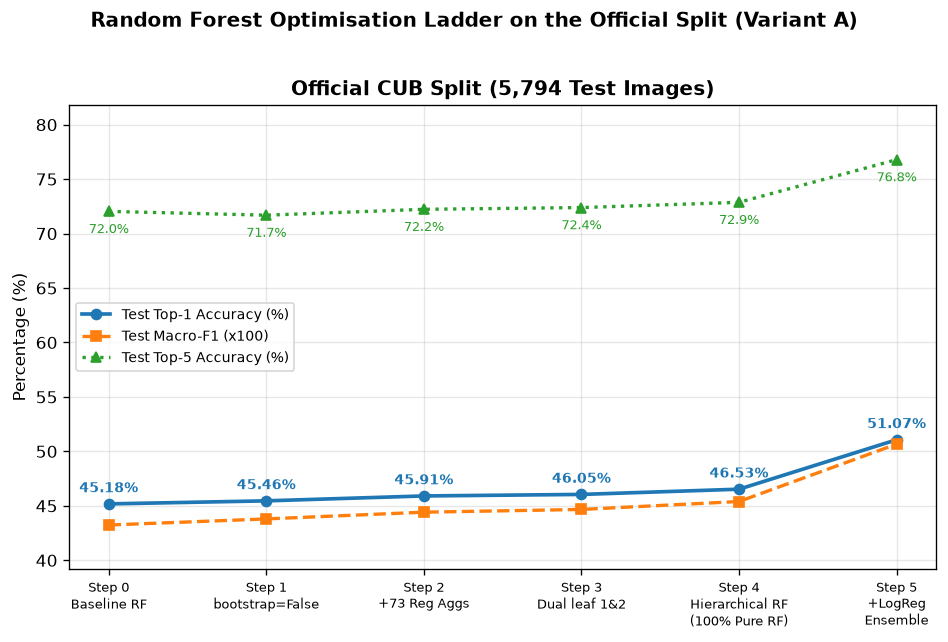

In [7]:
fig, ax = plt.subplots(figsize=(8, 5.2))

short_labels = [
    "Step 0\nBaseline RF",
    "Step 1\nbootstrap=False",
    "Step 2\n+73 Reg Aggs",
    "Step 3\nDual leaf 1&2",
    "Step 4\nHierarchical RF\n(100% Pure RF)",
    "Step 5\n+LogReg\nEnsemble",
]
x = np.arange(len(short_labels))

df_res, title = df_test_off, "Official CUB Split (5,794 Test Images)"
top1_vals = df_res["Test Top-1 (%)"].values
f1_vals = df_res["Test Macro-F1"].values * 100
top5_vals = df_res["Test Top-5 (%)"].values

ax.plot(x, top1_vals, marker="o", linewidth=2.2, label="Test Top-1 Accuracy (%)", color="#1f77b4")
ax.plot(x, f1_vals, marker="s", linewidth=2.0, linestyle="--", label="Test Macro-F1 (x100)", color="#ff7f0e")
ax.plot(x, top5_vals, marker="^", linewidth=2.0, linestyle=":", label="Test Top-5 Accuracy (%)", color="#2ca02c")

for xi, (v1, v5) in enumerate(zip(top1_vals, top5_vals)):
    ax.annotate(f"{v1:.2f}%", (xi, v1), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8.5, fontweight="bold", color="#1f77b4")
    ax.annotate(f"{v5:.1f}%", (xi, v5), textcoords="offset points", xytext=(0, -13), ha="center", fontsize=8, color="#2ca02c")

ax.set_xticks(x)
ax.set_xticklabels(short_labels, fontsize=8)
ax.set_ylabel("Percentage (%)")
ax.set_title(title, fontweight="bold")
ax.grid(True, alpha=0.3)
ax.set_ylim(min(f1_vals) - 4, max(top5_vals) + 5)
ax.legend(loc="center left", fontsize=8.5)

plt.suptitle("Random Forest Optimisation Ladder on the Official Split (Variant A)", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


### 5.1 How the Hierarchical Specialist RF and the Logistic Regression Blend Reduce Within-Family Confusions
Below we compare per-species F1 and the mean F1 of the 12 largest bird families on the official test split (`5,794` images) for **Step 0 (Baseline Tuned RF)**, **Step 4 (100% Pure Hierarchical RF)** and **Step 5 (Hierarchical RF + Logistic Regression)**:

In [8]:
preds_s0 = probas_off[STEP_NAMES[0]].argmax(axis=1) + 1
preds_s4 = probas_off[STEP_NAMES[4]].argmax(axis=1) + 1
preds_s5 = probas_off[STEP_NAMES[5]].argmax(axis=1) + 1

f1_per_cls_s0 = f1_score(y_te_off, preds_s0, average=None, labels=np.arange(1, 201))
f1_per_cls_s4 = f1_score(y_te_off, preds_s4, average=None, labels=np.arange(1, 201))
f1_per_cls_s5 = f1_score(y_te_off, preds_s5, average=None, labels=np.arange(1, 201))

species_comp = class_df.copy()
species_comp["F1_Step0_Base"] = f1_per_cls_s0
species_comp["F1_Step4_PureHierRF"] = f1_per_cls_s4
species_comp["F1_Step5_Hybrid"] = f1_per_cls_s5
species_comp["Gain_Step4_vs_Step0"] = species_comp["F1_Step4_PureHierRF"] - species_comp["F1_Step0_Base"]
species_comp["Gain_Step5_vs_Step0"] = species_comp["F1_Step5_Hybrid"] - species_comp["F1_Step0_Base"]

print(f"Species improved in F1 (Step 4 Pure Hierarchical RF vs Step 0) : {(species_comp['Gain_Step4_vs_Step0'] > 0).sum()} / 200 species")
print(f"Species improved in F1 (Step 5 +LogReg Ensemble vs Step 0)     : {(species_comp['Gain_Step5_vs_Step0'] > 0).sum()} / 200 species")

# Aggregate F1 gain by multi-species bird families (top 12 largest families)
top12_fams = multi_fam.head(12).index.tolist()
fam_f1_df = (
    species_comp[species_comp["family"].isin(top12_fams)]
    .groupby("family")[["class_id", "F1_Step0_Base", "F1_Step4_PureHierRF", "F1_Step5_Hybrid"]]
    .agg({"class_id": "count", "F1_Step0_Base": "mean", "F1_Step4_PureHierRF": "mean", "F1_Step5_Hybrid": "mean"})
    .rename(columns={"class_id": "n_species"})
    .loc[top12_fams]
)
fam_f1_df["Gain_PureRF (Step 4)"] = fam_f1_df["F1_Step4_PureHierRF"] - fam_f1_df["F1_Step0_Base"]
fam_f1_df["Gain_Hybrid (Step 5)"] = fam_f1_df["F1_Step5_Hybrid"] - fam_f1_df["F1_Step0_Base"]
print("\nMean Macro-F1 across the 12 largest multi-species bird families (Official Test Split):")
display(fam_f1_df.round(4))

Species improved in F1 (Step 4 Pure Hierarchical RF vs Step 0) : 129 / 200 species
Species improved in F1 (Step 5 +LogReg Ensemble vs Step 0)     : 170 / 200 species

Mean Macro-F1 across the 12 largest multi-species bird families (Official Test Split):


,n_species,F1_Step0_Base,F1_Step4_PureHierRF,F1_Step5_Hybrid,Gain_PureRF (Step 4),Gain_Hybrid (Step 5)
family,,,,,,
Warbler,25,0.4443,0.4502,0.4941,0.0058,0.0498
Sparrow,21,0.2873,0.3064,0.3306,0.0190,0.0433
Gull,8,0.4233,0.4683,0.4865,0.0450,0.0632
Flycatcher,7,0.2360,0.2378,0.3090,0.0018,0.0730
Tern,7,0.4067,0.4602,0.4704,0.0535,0.0637
Vireo,7,0.2890,0.2999,0.3475,0.0109,0.0585
Wren,7,0.2610,0.2953,0.3808,0.0343,0.1198
Woodpecker,6,0.7133,0.7673,0.8044,0.0540,0.0911
Kingfisher,5,0.5870,0.6096,0.6532,0.0226,0.0662


## 6. Summary of Findings for the Coursework Report

All results are on encoding A, the same input as the other classical models. Step 0 reproduces [`randomForest_encodingA.ipynb`](randomForest_encodingA.ipynb) exactly (`45.18%`, macro-F1 `0.4324`).

1. **Best Single `RandomForestClassifier` (Step 2)**:
   - `bootstrap=False` plus the **73 binary regional colour and pattern features** improves a single forest from **`45.18%` $\rightarrow$ `45.91%`** on the official test set (`0.4324` $\rightarrow$ `0.4442` macro-F1), a borderline-significant gain (`p = 5.05e-2`). Disabling bootstrap on its own gives no significant gain (`45.46%`, `p = 0.37`).
2. **Best 100% Pure Random Forest Architecture (Step 4 — Hierarchical 70-Family Specialist RF)**:
   - Predicting through the **70 bird families** (`62.3%` Top-1 / `81.3%` Top-3 family accuracy on the test set) with **within-family specialist forests** reaches **`46.53%`** (`0.4540` macro-F1, `+1.35` points, `p = 1.12e-3`) using random forests only.
3. **Best Model Overall (Step 5 — Hierarchical RF + Logistic Regression)**:
   - Blending the hierarchical forest (`55%`) with L2 logistic regression (`45%`) reaches **`51.07%`** Top-1 (`0.5067` macro-F1, `76.79%` Top-5), `+5.89` points over Step 0 (`p = 2.97e-33`). It improves the F1 of 170 of the 200 species and every one of the 12 largest families.
4. **Comparison with encoding C** ([`randomForestOptimisation.ipynb`](randomForestOptimisation.ipynb)):
   - The best model scores about the same on both encodings (`51.07%` on A vs `51.04%` on C), so the hidden-body-part flags are not needed for the final result. The intermediate single-forest steps gain less on A than on C (e.g. Step 4: `46.53%` vs `47.39%`), and the visibility-aware step (`48.65%` on C) has no encoding A equivalent.